In [60]:
#Task 1

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

np.random.seed(42)
RANDOM_STATE = 42
VAR_SMOOTHING = 1e-9

data = load_breast_cancer()

X = data.data.astype(float)
y = data.target.astype(int)
feature_names = data.feature_names
classes = np.unique(y)

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)
print("Class counts:", {int(c): int(np.sum(y == c)) for c in classes})

Dataset shape: (569, 30)
Classes: ['malignant' 'benign']
Class counts: {0: 212, 1: 357}


In [61]:

X = data.data.astype(float)
y = data.target.astype(int)
feature_names = data.feature_names
classes = np.unique(y)

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)
print("Class counts:", {int(c): int(np.sum(y == c)) for c in classes})

Dataset shape: (569, 30)
Classes: ['malignant' 'benign']
Class counts: {0: 212, 1: 357}


In [62]:
def train_test_split(X, y, test_size=0.2, seed=42):
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    train_indices, test_indices = [], []

    for label in np.unique(y):
        class_indices = np.where(y == label)[0].copy()
        rng.shuffle(class_indices)
        n_test = int(np.ceil(len(class_indices) * test_size))
        test_indices.extend(class_indices[:n_test])
        train_indices.extend(class_indices[n_test:])

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)
    train_indices = np.asarray(train_indices, dtype=int)
    test_indices = np.asarray(test_indices, dtype=int)
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, seed=RANDOM_STATE)

print("Training class counts:", {int(c): int(np.sum(y_train == c)) for c in classes})
print("Testing class counts:", {int(c): int(np.sum(y_test == c)) for c in classes})
print("Train/test shapes:", X_train.shape, X_test.shape)


train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)
train_std[train_std == 0] = 1.0
X_train_scaled = (X_train - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

Training class counts: {0: 169, 1: 285}
Testing class counts: {0: 43, 1: 72}
Train/test shapes: (454, 30) (115, 30)


In [63]:
class GaussianNaiveBayes:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_samples, n_features = X.shape
        self.theta_ = np.zeros((len(self.classes_), n_features), dtype=float)
        self.var_ = np.zeros((len(self.classes_), n_features), dtype=float)
        self.class_prior_ = np.zeros(len(self.classes_), dtype=float)

        epsilon = self.var_smoothing * np.var(X, axis=0).max()
        for idx, c in enumerate(self.classes_):
            X_c = X[y == c]
            self.theta_[idx, :] = X_c.mean(axis=0)
            self.var_[idx, :] = X_c.var(axis=0) + epsilon
            self.class_prior_[idx] = X_c.shape[0] / n_samples
        return self

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)
        # Shape: (samples, classes, features)
        joint = (
            -0.5 * np.sum(np.log(2.0 * np.pi * self.var_), axis=1)
            -0.5 * np.sum(((X[:, None, :] - self.theta_[None, :, :]) ** 2)
                          / self.var_[None, :, :], axis=2)
            + np.log(self.class_prior_)[None, :]
        )
        # Normalize log probabilities using log-sum-exp.
        row_max = np.max(joint, axis=1, keepdims=True)
        log_sum_exp = row_max + np.log(np.sum(np.exp(joint - row_max), axis=1, keepdims=True))
        return joint - log_sum_exp

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        log_probs = self.predict_log_proba(X)
        return self.classes_[np.argmax(log_probs, axis=1)]

In [64]:
X_tiny = np.array([[1.0], [3.0], [5.0], [7.0]])
y_tiny = np.array([0, 0, 1, 1])
tiny_model = GaussianNaiveBayes(var_smoothing=0.0).fit(X_tiny, y_tiny)

manual_mean_0 = np.mean([1.0, 3.0])
manual_var_0 = np.var([1.0, 3.0])  # population variance, ddof=0
x_value = 2.0
manual_likelihood_0 = (1 / np.sqrt(2 * np.pi * manual_var_0)) * np.exp(
    -((x_value - manual_mean_0) ** 2) / (2 * manual_var_0)
)

model_mean_0 = tiny_model.theta_[0, 0]
model_var_0 = tiny_model.var_[0, 0]
model_likelihood_0 = (1 / np.sqrt(2 * np.pi * model_var_0)) * np.exp(
    -((x_value - model_mean_0) ** 2) / (2 * model_var_0)
)

print("Manual class-0 mean:", manual_mean_0, "| Model:", model_mean_0)
print("Manual class-0 variance:", manual_var_0, "| Model:", model_var_0)
print("Manual Gaussian likelihood at x=2:", manual_likelihood_0)
print("Model Gaussian likelihood at x=2:", model_likelihood_0)
assert np.allclose(manual_mean_0, model_mean_0)
assert np.allclose(manual_var_0, model_var_0)
assert np.allclose(manual_likelihood_0, model_likelihood_0)
print("Sanity test passed.")

Manual class-0 mean: 2.0 | Model: 2.0
Manual class-0 variance: 1.0 | Model: 1.0
Manual Gaussian likelihood at x=2: 0.3989422804014327
Model Gaussian likelihood at x=2: 0.3989422804014327
Sanity test passed.


In [65]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)


In [66]:
#Task 3 metrics evaluation 
def accuracy(y_true, y_pred):
    correct = np.sum(y_true == y_pred)
    total = len(y_true)
    return correct / total 


In [67]:
y_true = np.array([0, 1, 1, 0, 1])
y_pred = np.array([0, 1, 0, 0, 1])

acc = accuracy(y_true, y_pred)

print("Accuracy:", acc)

Accuracy: 0.8


In [68]:
def confusion_matrix(y_true, y_pred, classes):
    matrix = np.zeros((len(classes), len(classes)), dtype=int)

    for i, actual_class in enumerate(classes):
        for j, predicted_class in enumerate(classes):
            matrix[i, j] = np.sum(
                (y_true == actual_class) & (y_pred == predicted_class)
            )

    return matrix


In [69]:
classes = np.array([0, 1])

cm = confusion_matrix(y_true, y_pred, classes)

print(cm)

[[2 0]
 [1 2]]


In [70]:
def precision_recall_f1(y_true, y_pred, classes):

    cm = confusion_matrix(y_true, y_pred, classes)

    results = {}

    for i, c in enumerate(classes):

        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP

        precision = TP / (TP + FP) if (TP + FP) != 0 else 0
        recall = TP / (TP + FN) if (TP + FN) != 0 else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) != 0 else 0
        )

        results[c] = {
            "precision": precision,
            "recall": recall,
            "f1": f1
        }

    macro = {
        metric: np.mean([results[c][metric] for c in classes])
        for metric in ["precision", "recall", "f1"]
    }

    return results, macro

In [71]:
results, macro = precision_recall_f1(y_true, y_pred, classes)

print("Per-class results:")
print(results)

print("\nMacro Average:")
print(macro)

Per-class results:
{np.int64(0): {'precision': np.float64(0.6666666666666666), 'recall': np.float64(1.0), 'f1': np.float64(0.8)}, np.int64(1): {'precision': np.float64(1.0), 'recall': np.float64(0.6666666666666666), 'f1': np.float64(0.8)}}

Macro Average:
{'precision': np.float64(0.8333333333333333), 'recall': np.float64(0.8333333333333333), 'f1': np.float64(0.8)}


In [72]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [73]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data.astype(float)
y = data.target.astype(int)

classes = np.unique(y)
feature_names = data.feature_names

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)
print("Class counts:", {int(c): int(np.sum(y == c)) for c in classes})

Dataset shape: (569, 30)
Classes: ['malignant' 'benign']
Class counts: {0: 212, 1: 357}


In [74]:
def train_test_split(X, y, test_size=0.2, seed=42):
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    train_indices, test_indices = [], []

    for label in np.unique(y):
        class_indices = np.where(y == label)[0].copy()
        rng.shuffle(class_indices)
        n_test = int(np.ceil(len(class_indices) * test_size))
        test_indices.extend(class_indices[:n_test])
        train_indices.extend(class_indices[n_test:])

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    train_indices = np.asarray(train_indices, dtype=int)
    test_indices = np.asarray(test_indices, dtype=int)

    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, seed=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training class counts:",
      {int(c): int(np.sum(y_train == c)) for c in classes})

print("Testing class counts:",
      {int(c): int(np.sum(y_test == c)) for c in classes})

Training shape: (454, 30)
Testing shape: (115, 30)
Training class counts: {0: 169, 1: 285}
Testing class counts: {0: 43, 1: 72}


In [76]:
class GaussianNaiveBayes:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_samples, n_features = X.shape
        self.theta_ = np.zeros((len(self.classes_), n_features), dtype=float)
        self.var_ = np.zeros((len(self.classes_), n_features), dtype=float)
        self.class_prior_ = np.zeros(len(self.classes_), dtype=float)

        epsilon = self.var_smoothing * np.var(X, axis=0).max()
        for idx, c in enumerate(self.classes_):
            X_c = X[y == c]
            self.theta_[idx, :] = X_c.mean(axis=0)
            self.var_[idx, :] = X_c.var(axis=0) + epsilon
            self.class_prior_[idx] = X_c.shape[0] / n_samples
        return self

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)
        # Shape: (samples, classes, features)
        joint = (
            -0.5 * np.sum(np.log(2.0 * np.pi * self.var_), axis=1)
            -0.5 * np.sum(((X[:, None, :] - self.theta_[None, :, :]) ** 2)
                          / self.var_[None, :, :], axis=2)
            + np.log(self.class_prior_)[None, :]
        )
        # Normalize log probabilities using log-sum-exp.
        row_max = np.max(joint, axis=1, keepdims=True)
        log_sum_exp = row_max + np.log(np.sum(np.exp(joint - row_max), axis=1, keepdims=True))
        return joint - log_sum_exp

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        log_probs = self.predict_log_proba(X)
        return self.classes_[np.argmax(log_probs, axis=1)]

In [77]:
model = GaussianNaiveBayes()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [78]:
y_pred = model.predict(X_test)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [0 0 1 1 1 1 0 1 1 1]
Predicted labels: [0 0 1 0 1 1 0 1 1 1]


In [79]:
acc = accuracy(y_test, y_pred)

print("Accuracy:", acc)

Accuracy: 0.9391304347826087


In [80]:
cm = confusion_matrix(y_test, y_pred, classes)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[39  4]
 [ 3 69]]


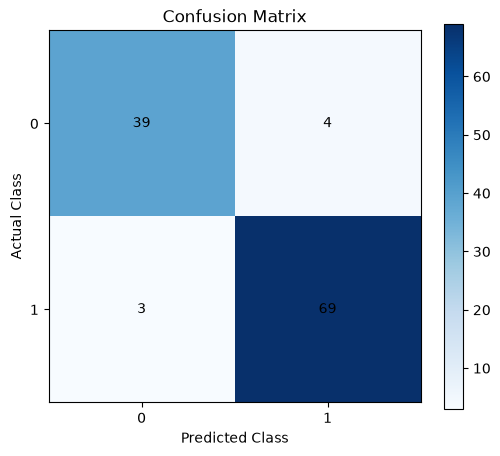

In [81]:
plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [82]:
results, macro = precision_recall_f1(
    y_test, y_pred, classes
)

print("Per-class results:")
print(results)

print("\nMacro Average:")
print(macro)

Per-class results:
{np.int64(0): {'precision': np.float64(0.9285714285714286), 'recall': np.float64(0.9069767441860465), 'f1': np.float64(0.9176470588235294)}, np.int64(1): {'precision': np.float64(0.9452054794520548), 'recall': np.float64(0.9583333333333334), 'f1': np.float64(0.9517241379310345)}}

Macro Average:
{'precision': np.float64(0.9368884540117417), 'recall': np.float64(0.9326550387596899), 'f1': np.float64(0.9346855983772819)}


#Task 4:Expermints Breaking the naive assumption

In [83]:
print(data.feature_names[:10])

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension']


In [84]:
feature_index = list(feature_names).index("mean radius")

print("Feature index:", feature_index)

Feature index: 0


In [85]:
feature_index = 0

X_train_feature = X_train[:, feature_index]
X_test_feature = X_test[:, feature_index]

print(X_train_feature.shape)
print(X_test_feature.shape)

(454,)
(115,)


In [86]:
X_train_1 = np.column_stack((X_train, X_train_feature))
X_test_1 = np.column_stack((X_test, X_test_feature))

print("Original shape:", X_train.shape)
print("New shape:", X_train_1.shape)

Original shape: (454, 30)
New shape: (454, 31)


In [87]:
copy_counts = [1, 3, 5, 10]

accuracy_scores = []
confidence_scores = []

for n in copy_counts:
    X_train_aug = np.column_stack(
        [X_train] + [X_train_feature.reshape(-1, 1)] * n
    )

    X_test_aug = np.column_stack(
        [X_test] + [X_test_feature.reshape(-1, 1)] * n
    )

    model_copy = GaussianNaiveBayes()
    model_copy.fit(X_train_aug, y_train)

    predictions = model_copy.predict(X_test_aug)
    probabilities = model_copy.predict_proba(X_test_aug)

    acc = accuracy(y_test, predictions)
    avg_confidence = np.mean(np.max(probabilities, axis=1))

    accuracy_scores.append(acc)
    confidence_scores.append(avg_confidence)

    print(f"Copies: {n}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Average confidence: {avg_confidence:.4f}")
    print()

Copies: 1
Accuracy: 0.9391
Average confidence: 0.9947

Copies: 3
Accuracy: 0.9478
Average confidence: 0.9973

Copies: 5
Accuracy: 0.9391
Average confidence: 0.9954

Copies: 10
Accuracy: 0.9391
Average confidence: 0.9982



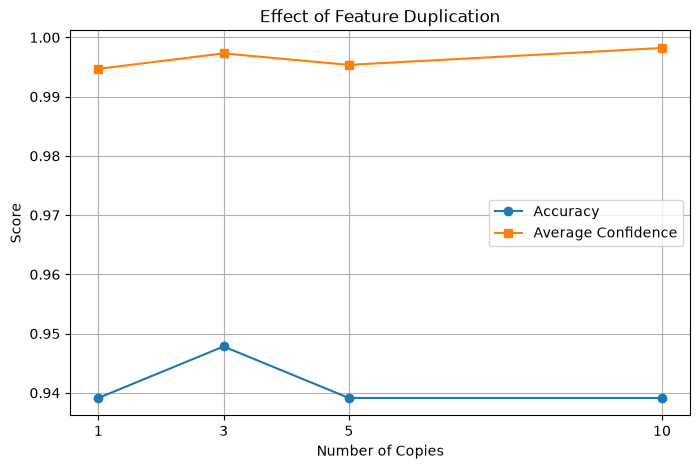

In [88]:
plt.figure(figsize=(8, 5))

plt.plot(copy_counts, accuracy_scores, marker='o', label='Accuracy')
plt.plot(copy_counts, confidence_scores, marker='s', label='Average Confidence')

plt.xlabel("Number of Copies")
plt.ylabel("Score")
plt.title("Effect of Feature Duplication")
plt.xticks(copy_counts)
plt.legend()
plt.grid(True)
plt.show()

Task 4: breaking the Naive Assumption  Results:

This experiment replicated the mean radius feature 1, 3, 5, and 10 times.
from the results we can conclude that accuracy did not change much when average confidence was still high and increased reaching approximately 99.82% in case of 10 copies. why this happened? because duplicated features contained the same information with no much difference.gaussian naive bayes treats them as conditionally independent features.so the model counted the same evidence again and again which led to overconfident predictions with no improvement in accuacy. this shows the effects of violation of naives bayes conditional independence assumption.


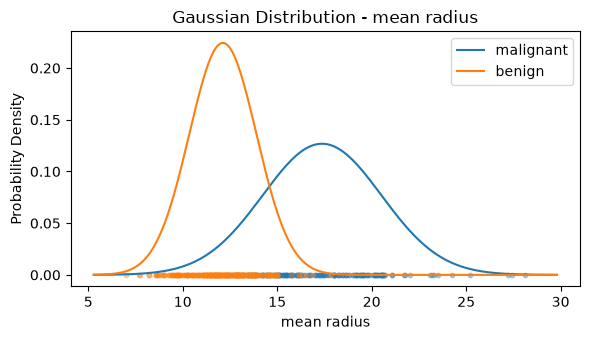

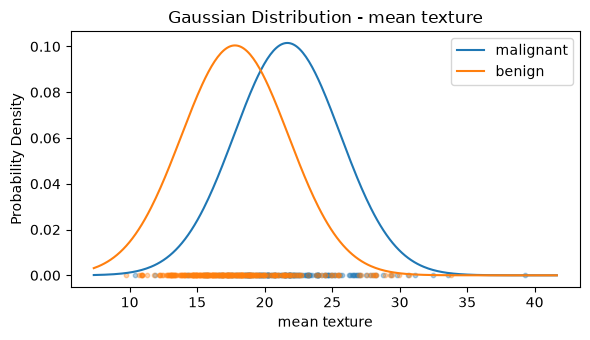

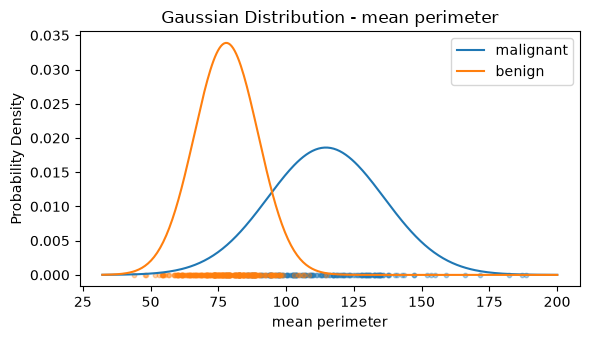

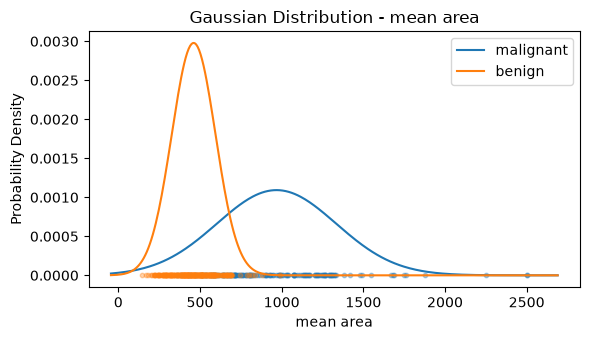

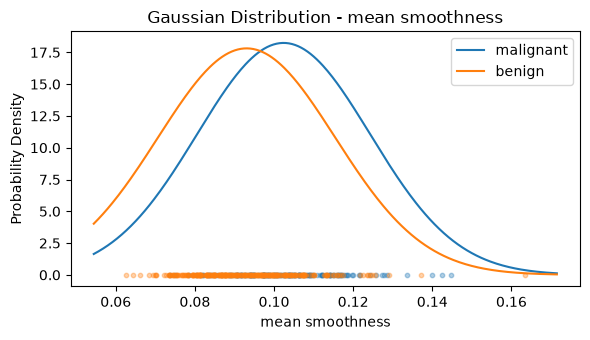

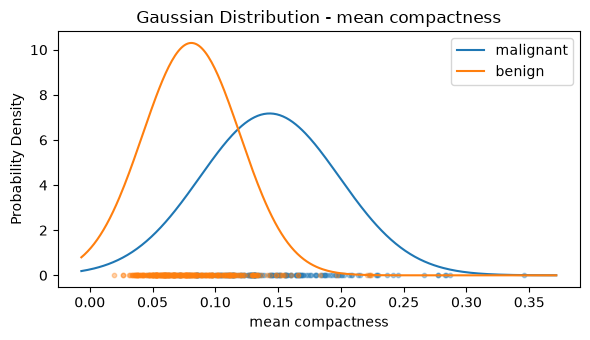

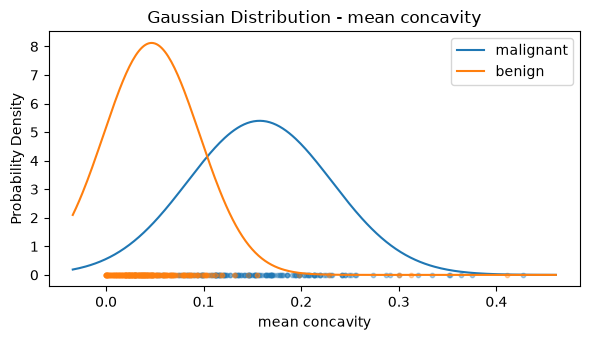

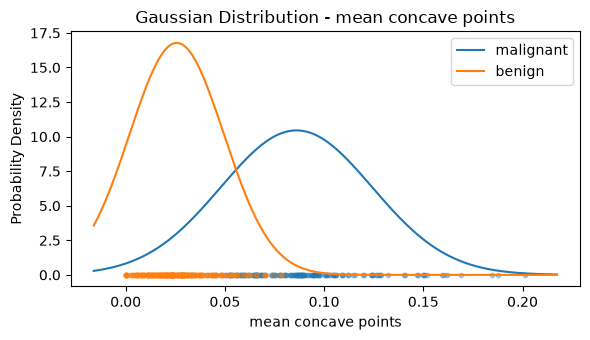

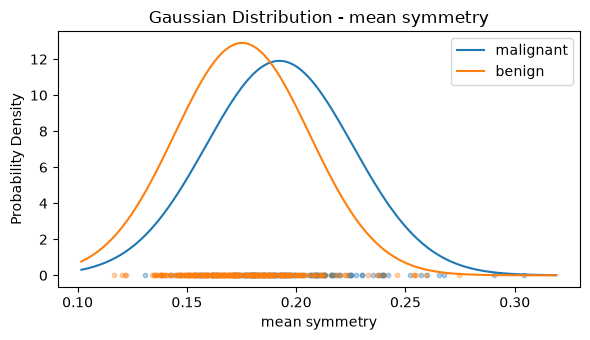

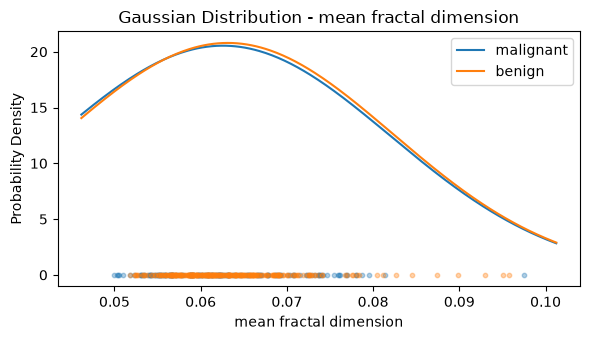

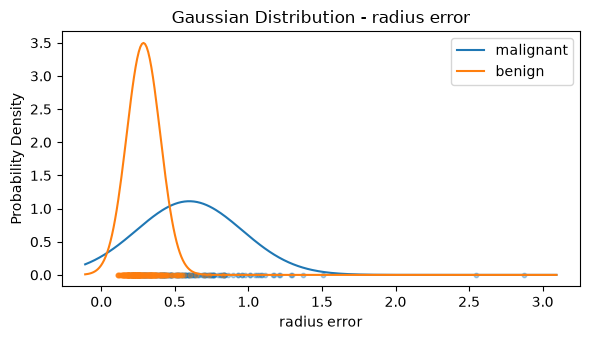

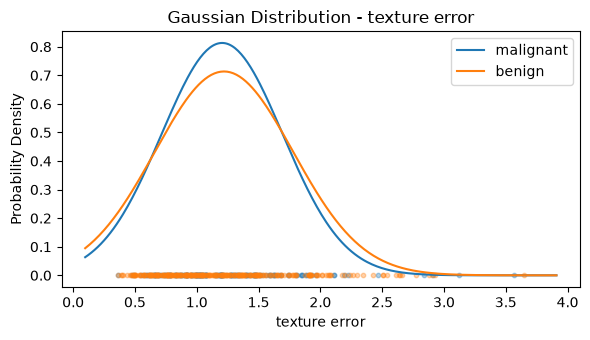

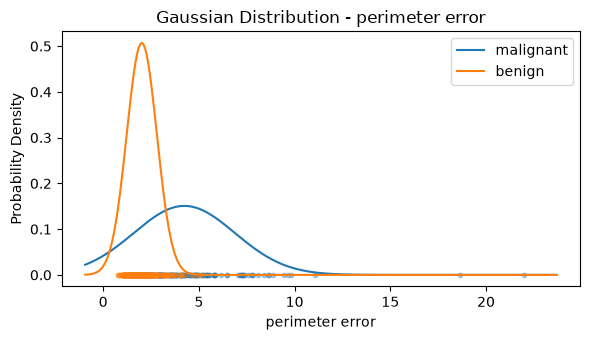

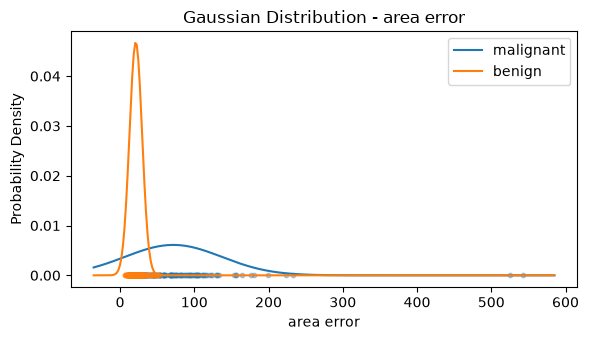

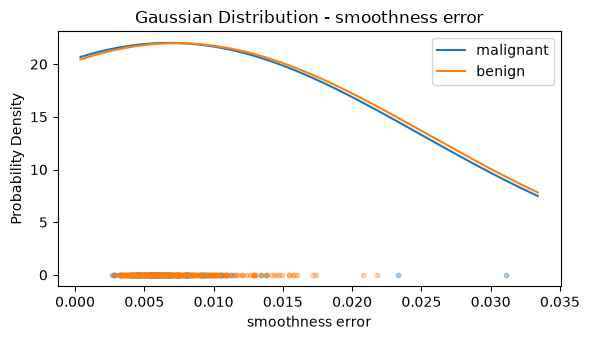

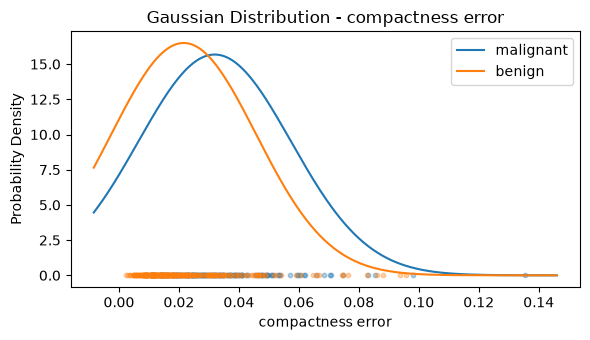

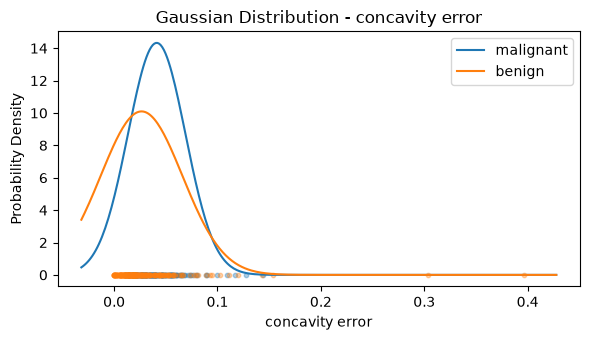

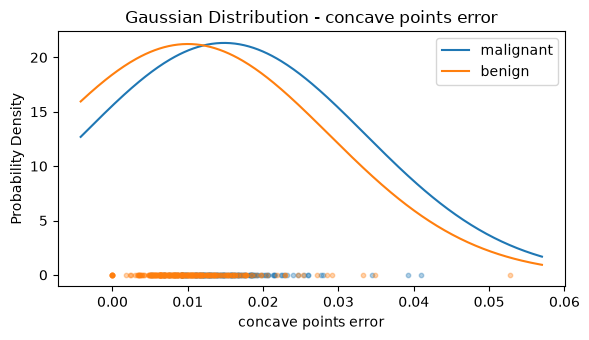

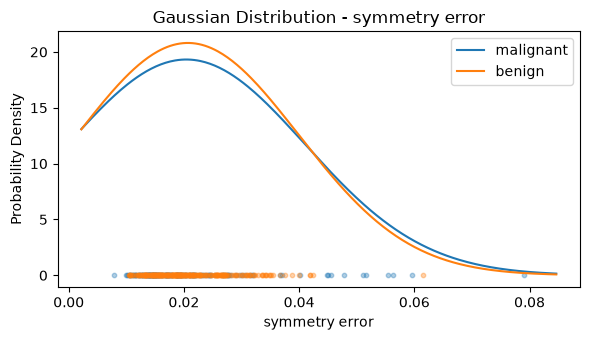

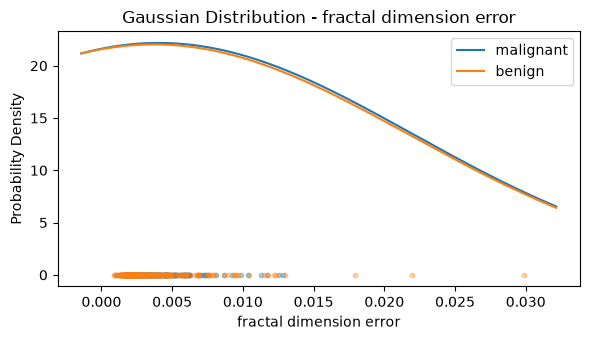

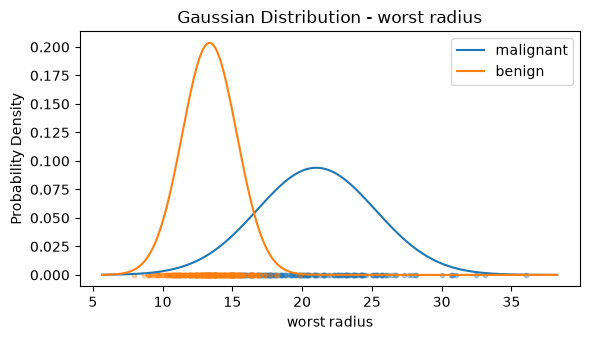

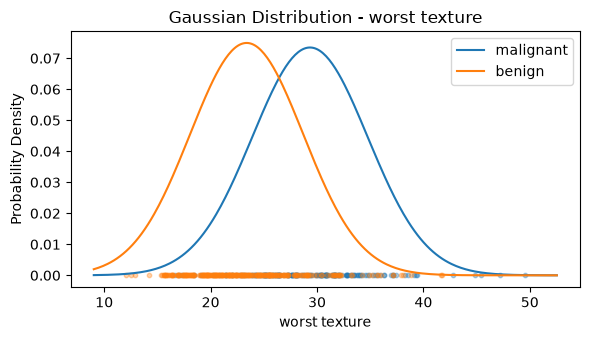

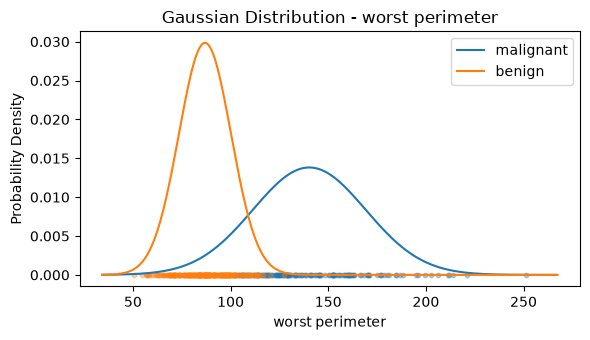

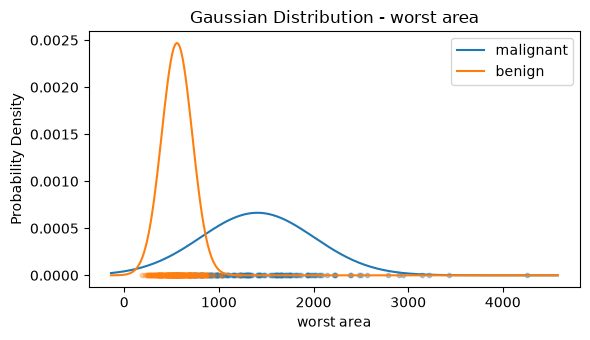

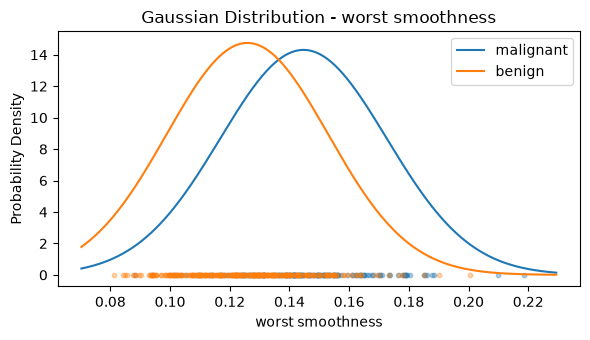

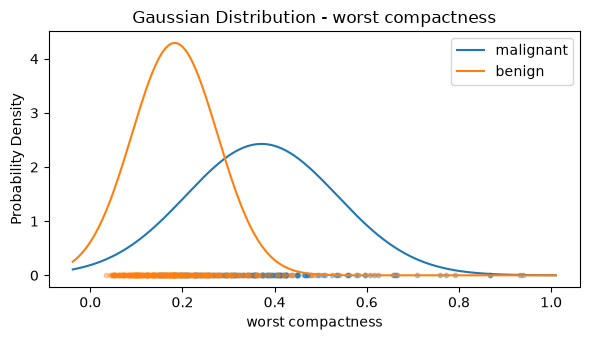

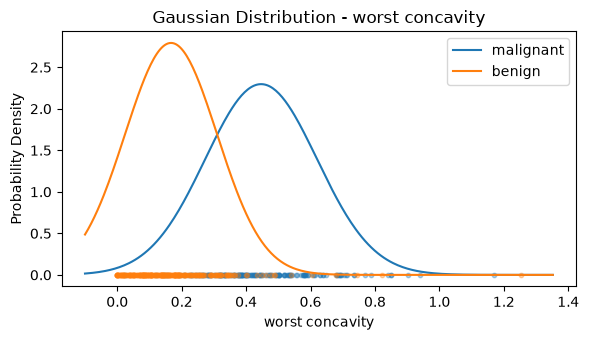

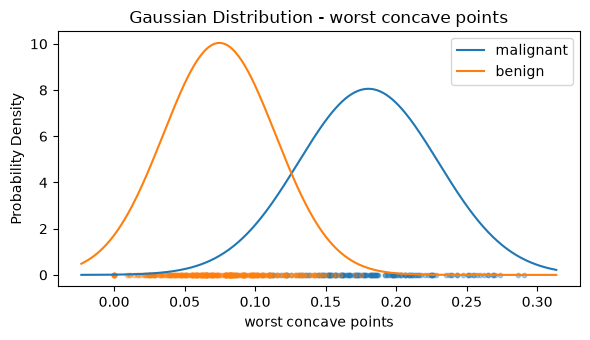

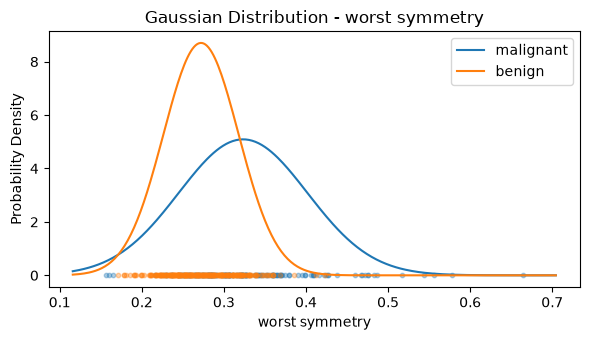

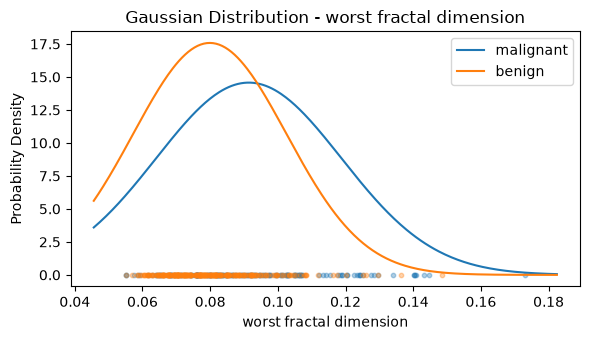

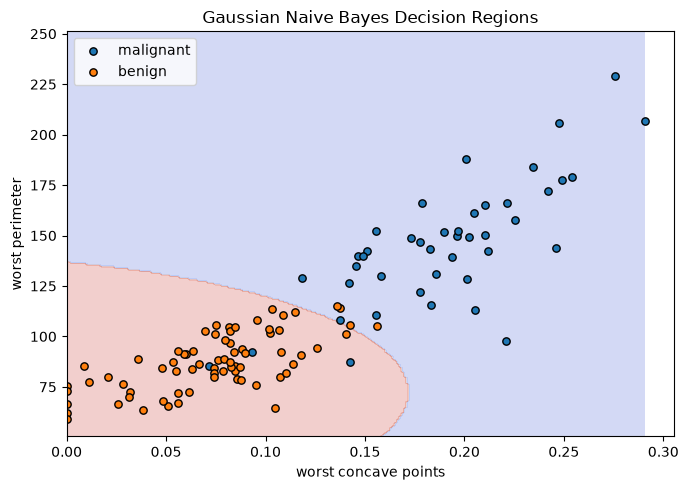

In [89]:
#Task 5

# Task 5 - Visualization

# Fit Gaussian Naive Bayes on original training data
visual_model = GaussianNaiveBayes()
visual_model.fit(X_train, y_train)

# Part 1: Plot Gaussian curves for every feature

for j, feature in enumerate(feature_names):

    fig, ax = plt.subplots(figsize=(6, 3.5))

    x_min = X_train[:, j].min()
    x_max = X_train[:, j].max()

    padding = 0.08 * (x_max - x_min)
    grid = np.linspace(x_min - padding, x_max + padding, 300)

    for class_idx, c in enumerate(classes):

        mean = visual_model.theta_[class_idx, j]
        variance = visual_model.var_[class_idx, j]

        density = (1 / np.sqrt(2 * np.pi * variance)) * np.exp(
            -((grid - mean) ** 2) / (2 * variance)
        )

        ax.plot(
            grid,
            density,
            label=data.target_names[c]
        )

        points = X_train[y_train == c, j]

        ax.scatter(
            points,
            np.zeros_like(points),
            s=10,
            alpha=0.35
        )

    ax.set_title(f"Gaussian Distribution - {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Probability Density")
    ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)


# Part 2: Decision Regions

# Calculate feature separation inside Task 5
class_means = np.array([
    X_train[y_train == c].mean(axis=0)
    for c in classes
])

class_stds = np.array([
    X_train[y_train == c].std(axis=0)
    for c in classes
])

pooled_scale = np.sqrt(np.mean(class_stds ** 2, axis=0))
pooled_scale[pooled_scale == 0] = 1.0

separation = np.abs(class_means[1] - class_means[0]) / pooled_scale

# Select the two most informative features
feature_pair = np.argsort(separation)[-2:][::-1]

X_train_2d = X_train[:, feature_pair]
X_test_2d = X_test[:, feature_pair]

# Train model using only two features
region_model = GaussianNaiveBayes()
region_model.fit(X_train_2d, y_train)

# Create mesh grid
x0_min, x0_max = X_train_2d[:, 0].min(), X_train_2d[:, 0].max()
x1_min, x1_max = X_train_2d[:, 1].min(), X_train_2d[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(x0_min, x0_max, 250),
    np.linspace(x1_min, x1_max, 250)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Predict every point in the grid
Z = region_model.predict(grid_points).reshape(xx.shape)

# Plot decision regions
fig, ax = plt.subplots(figsize=(7, 5))

ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

for c in classes:

    mask = y_test == c

    ax.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        label=data.target_names[c],
        edgecolors="black",
        s=28
    )

ax.set_title("Gaussian Naive Bayes Decision Regions")
ax.set_xlabel(feature_names[feature_pair[0]])
ax.set_ylabel(feature_names[feature_pair[1]])
ax.legend()

plt.tight_layout()
plt.show()


In [90]:
# Task 6
from sklearn.naive_bayes import GaussianNB

our_model = GaussianNaiveBayes(var_smoothing=VAR_SMOOTHING).fit(X_train, y_train)
sk_model = GaussianNB(var_smoothing=VAR_SMOOTHING).fit(X_train, y_train)

print("theta_ match:", np.allclose(our_model.theta_, sk_model.theta_))
print("var_ match:", np.allclose(our_model.var_, sk_model.var_))
print("class_prior_ match:", np.allclose(our_model.class_prior_, sk_model.class_prior_))
our_probabilities = our_model.predict_proba(X_test)
sk_probabilities = sk_model.predict_proba(X_test)
print("predict_proba match:", np.allclose(our_probabilities, sk_probabilities))
agreement = np.mean(our_model.predict(X_test) == sk_model.predict(X_test)) * 100
print("Prediction agreement (%):", agreement)

# Repeat the required comparison on standardized data as an additional check.
our_scaled = GaussianNaiveBayes(var_smoothing=VAR_SMOOTHING).fit(X_train_scaled, y_train)
sk_scaled = GaussianNB(var_smoothing=VAR_SMOOTHING).fit(X_train_scaled, y_train)
print("Scaled theta/var/prior match:",
      np.allclose(our_scaled.theta_, sk_scaled.theta_),
      np.allclose(our_scaled.var_, sk_scaled.var_),
      np.allclose(our_scaled.class_prior_, sk_scaled.class_prior_))
print("Scaled predict_proba match:",
      np.allclose(our_scaled.predict_proba(X_test_scaled),
                  sk_scaled.predict_proba(X_test_scaled)))

theta_ match: True
var_ match: True
class_prior_ match: True
predict_proba match: True
Prediction agreement (%): 100.0
Scaled theta/var/prior match: True True True
Scaled predict_proba match: True
